# ⚡ LAB: Machine Learning for Time Series Forecasting

### Learning goals
1. Build a seasonal naïve **Lag-7 day** benchmark.
2. Construct **leakage-safe** time-series and calendar features.
3. Compare **Linear Regression, Random Forest, and SVR**.
4. Explain why **SVR needs scaling** and how RF hyperparameters affect performance.
5. Select models using a **validation** period, then evaluate once on held-out **test** data.
6. Investigate where errors occur in the electricity demand profile.

**Submission:** completed code cells, validation ranking, final test comparison, one plot, and short written conclusions.

📚 Course background: [Lag-7](https://drmatson.github.io/energy_informatics/16_ml_baseline_lag7d.html) · [Linear Regression](https://drmatson.github.io/energy_informatics/17_ml_baseline_LR.html) · [Random Forest](https://drmatson.github.io/energy_informatics/18_ml_RF.html) · [SVR](https://drmatson.github.io/energy_informatics/19_ml_SVM.html)

## 0. Setup and data loading (provided)

The CSV is loaded **directly from GitHub** using the same Kaggle competition dataset as in the course materials. No local CSV files are needed. It contains 8,592 hourly samples and columns including `time`, `consumption`, `temp`, and `el_price`.

**Target:** `consumption` (kWh, following the course examples). **Time:** `time`. The CSV stores **timezone-naive local clock times** that follow Estonia daylight-saving transitions. We interpret these as `Europe/Tallinn`: two different 03:00 records on **2021-10-31** are preserved as separate real hours, while 03:00 on **2022-03-27** does not exist. The resulting timezone-aware index is unique and hourly in elapsed time.

Other columns may describe **measurements at the target time**. We deliberately exclude actual future weather and future observed prices from the base models: an operational day-ahead forecast could use these only if their values were genuinely known in advance (e.g. weather forecasts or published day-ahead prices).

Only `consumption` is required to complete this lab; missing values in optional weather columns do not affect training.

https://www.kaggle.com/competitions/predict-electricity-consumption/data

Loaded 8,592 hours: 2021-09-01 00:00:00+03:00 → 2022-08-24 23:00:00+03:00
Mean hourly consumption: 1.046 kWh
Other dataset columns: ['temp', 'dwpt', 'rhum', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'coco', 'el_price']


,temp,dwpt,rhum,prcp,snow,wdir,wspd,wpgt,pres,coco,el_price,consumption
time,,,,,,,,,,,,
2021-09-01 00:00:00+03:00,11.2,10.3,94.0,NaN,NaN,320.0,7.2,16.7,1012.6,2.0,0.09016,0.577
2021-09-01 01:00:00+03:00,10.7,9.6,93.0,NaN,NaN,320.0,7.2,13.0,1012.6,2.0,0.09251,0.594
2021-09-01 02:00:00+03:00,9.9,9.0,94.0,NaN,NaN,320.0,7.2,13.0,1012.2,2.0,0.08890,0.685
2021-09-01 03:00:00+03:00,10.0,8.4,90.0,NaN,NaN,330.0,7.2,13.0,1011.9,1.0,0.08735,1.016
2021-09-01 04:00:00+03:00,9.0,8.1,94.0,NaN,NaN,300.0,3.6,13.0,1011.4,2.0,0.08688,0.677


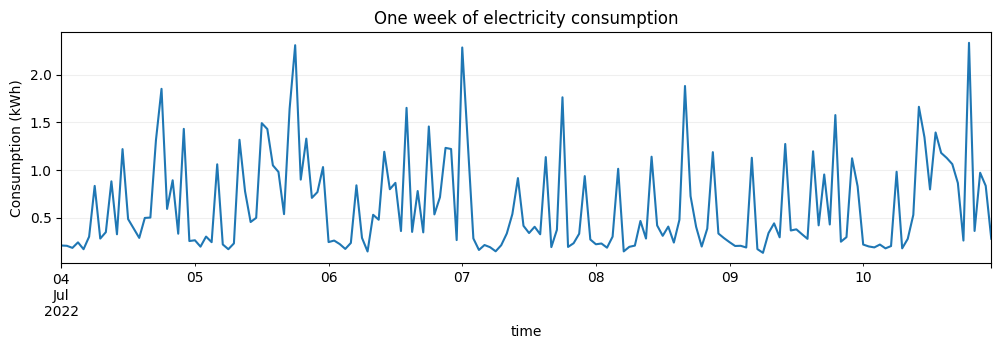

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
DATA_URL = (
    "https://raw.githubusercontent.com/drmatson/energy_informatics/"
    "main/2025/data/kaggle_competition_dataset.csv"
)

# Read the dataset directly from GitHub. Its times are Tallinn wall-clock times.
# The CSV has 03:00 twice on 2021-10-31 (autumn DST), and no 03:00
# on 2022-03-27 (spring DST). Keep both real autumn observations.
raw = pd.read_csv(DATA_URL)
local_clock = pd.to_datetime(raw["time"], errors="raise")
aware_times = local_clock.dt.tz_localize(
    "Europe/Tallinn", ambiguous="infer", nonexistent="raise"
)
df = raw.drop(columns="time")
df.index = pd.DatetimeIndex(aware_times, name="time")
df = df.sort_index()

assert df.index.is_unique, "Each timezone-aware instant must be unique."
assert df.index.is_monotonic_increasing
assert (df.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), (
    "Expected consecutive elapsed hours after handling the DST transitions."
)

demand = pd.to_numeric(df["consumption"], errors="raise").rename("consumption_kWh")
assert demand.notna().all(), "Unexpected missing target values."

print(f"Loaded {len(demand):,} hours: {demand.index.min()} → {demand.index.max()}")
print(f"Mean hourly consumption: {demand.mean():.3f} kWh")
print("Other dataset columns:", list(df.columns.drop("consumption")))
display(df.head())

fig, ax = plt.subplots(figsize=(12, 3))
demand.loc["2022-07-04":"2022-07-10"].plot(ax=ax, title="One week of electricity consumption")
ax.set_ylabel("Consumption (kWh)")
ax.grid(alpha=0.2)
plt.show()


### Forecasting protocol — read this carefully

- At the **start of each forecast day**, predict its hourly electricity consumption values (normally 24; 23 or 25 on DST transition days).
- For an hour at timestamp `t`, `lag_24`, `lag_48`, and `lag_168` are available at the start of that day. **`lag_1` would not be available for the whole next day**.
- This is a *rolling day-ahead* test: at each new midnight, yesterday's observed consumption becomes available. It is **not** a single forecast of the whole test period issued on July 1.
- **Training:** September 2021–April 2022; **validation:** May–June 2022; **test:** July–August 24, 2022.
- Select the algorithm and hyperparameters **on validation only**. Evaluate the selected ML method against Lag-7 on the held-out test data.

Our primary metric is **NRMSE (%)**, normalized by the mean consumption in each evaluated period:
`NRMSE (%) = 100 × RMSE / mean(actual consumption)`. Lower is better. Also report MAE in kWh.


In [2]:
TRAIN_END = pd.Timestamp("2022-05-01", tz="Europe/Tallinn")
VALID_END = pd.Timestamp("2022-07-01", tz="Europe/Tallinn")

def evaluate(y_true, y_pred):
    y = np.asarray(y_true, dtype=float).ravel()
    p = np.asarray(y_pred, dtype=float).ravel()
    assert len(y) == len(p) and len(y) > 0
    assert np.isfinite(y).all() and np.isfinite(p).all()
    mae = mean_absolute_error(y, p)
    rmse = np.sqrt(mean_squared_error(y, p))
    return {"MAE (kWh)": mae, "NRMSE (%)": 100 * rmse / np.mean(y)}

def show_scores(scores):
    return pd.DataFrame(scores).T.sort_values("NRMSE (%)").round(3)


## 1. Seasonal baseline

**Task 1.** Use the value at the same elapsed hour **7 days ago** to predict demand over May–June 2022. Report MAE and NRMSE.

**Hint:** a normal week contains `24 * 7 = 168` elapsed hours. `demand.shift(168)` aligns past observations by elapsed hour; around a DST transition, this can differ by one hour from the same local clock time last week.

In [3]:
validation_y = demand.loc[(demand.index >= TRAIN_END) & (demand.index < VALID_END)]

# TODO 1: compute a Lag-7 prediction for every validation timestamp.
# Assign a pandas Series to baseline_valid, aligned with validation_y.
raise NotImplementedError("Task 1: create baseline_valid using shift(168).")

baseline_valid_score = evaluate(validation_y, baseline_valid)
print("Lag-7 validation:", baseline_valid_score)

NotImplementedError: Task 1: create baseline_valid using shift(168).

**Quick reasoning:** What could make this baseline inaccurate? Think of public holidays, unusual weather, or changes in demand between weeks.

**Your answer:** ...

## 2. Build leakage-safe features

**Task 2.** Complete the time-series features using `shift` and `rolling`:

- `lag_24`: demand 24 hours ago.
- `lag_48`: demand 48 hours ago.
- `lag_168`: demand 168 hours ago.
- `mean_previous_day`: mean of the 24 values from **`t-47` through `t-24`** (inclusive), not from the target day.

Calendar features are provided: hour-of-day and day-of-week encoded cyclically, using the dataset timestamps. The features represent the **target timestamp**, which is known in advance.

In [ ]:
frame = demand.to_frame(name="target")

# TODO 2: fill in these four feature assignments. Do not use current/future target values.
raise NotImplementedError("Task 2: create lag_24, lag_48, lag_168 and mean_previous_day.")

hour = frame.index.hour.to_numpy()
dow = frame.index.dayofweek.to_numpy()
frame["hour_sin"] = np.sin(2 * np.pi * hour / 24)
frame["hour_cos"] = np.cos(2 * np.pi * hour / 24)
frame["dow_sin"] = np.sin(2 * np.pi * dow / 7)
frame["dow_cos"] = np.cos(2 * np.pi * dow / 7)
frame["weekend"] = (dow >= 5).astype(int)

frame = frame.dropna().copy()
lag_features = ["lag_24", "lag_48", "lag_168"]
full_features = lag_features + [
    "mean_previous_day", "hour_sin", "hour_cos",
    "dow_sin", "dow_cos", "weekend"
]

assert frame.index.is_monotonic_increasing
assert not frame[full_features + ["target"]].isna().any().any()
display(frame.head())

**Check your understanding:** Why is `demand.rolling(24).mean()` **unsafe**, but `demand.shift(24).rolling(24).mean()` safe for this next-day forecasting task?

**Your answer:** ...

### Chronological train / validation / test split (provided)

We deliberately **do not shuffle**. Hyperparameters are selected on validation, and the final test period is left untouched until Task 6. These are fixed calendar boundaries for the supplied dataset.

In [ ]:
train = frame.loc[frame.index < TRAIN_END].copy()
valid = frame.loc[(frame.index >= TRAIN_END) & (frame.index < VALID_END)].copy()
test = frame.loc[frame.index >= VALID_END].copy()

assert len(train) > 0 and len(valid) > 0 and len(test) > 0
assert train.index.max() < valid.index.min() < test.index.min()
assert valid.index.equals(validation_y.index)

print("Train:", len(train), train.index.min(), "→", train.index.max())
print("Validation:", len(valid), valid.index.min(), "→", valid.index.max())
print("Test:", len(test), test.index.min(), "→", test.index.max())

validation_results = {"Lag-7 baseline": baseline_valid_score}
validation_predictions = {"Lag-7 baseline": baseline_valid}
fitted_models = {}

def train_and_score(name, model, features):
    """Fit on train, predict validation, store result for later comparison."""
    model.fit(train[features], train["target"])
    pred = pd.Series(model.predict(valid[features]), index=valid.index, name=name)
    fitted_models[name] = (model, list(features))
    validation_predictions[name] = pred
    validation_results[name] = evaluate(valid["target"], pred)
    print(f"{name}: {validation_results[name]}")

## 3. Linear Regression

**Task 3.** Train two `LinearRegression` models with the helper `train_and_score(name, model, features)`:

- **LR | lags** → `lag_features`
- **LR | full** → `full_features`

Compare their validation errors. Does adding calendar/history features help?

In [ ]:
# TODO 3: train both linear regression variants.
raise NotImplementedError("Task 3: call train_and_score twice with LinearRegression().")

display(show_scores(validation_results))

**Your interpretation:** Which LR feature set works better on validation? State the NRMSE difference in percentage points.

**Your answer:** ...

## 4. Random Forest

**Task 4.** Train two forests with the **same feature set** (`full_features`) but different tree depths:

- `RF | depth 6` → `max_depth=6`
- `RF | depth 16` → `max_depth=16`

Use `RandomForestRegressor(n_estimators=100, min_samples_leaf=4, random_state=42, n_jobs=-1, ...)`.

**Challenge:** Which depth gives lower validation NRMSE? Is the deeper model always better? Why might a forest struggle to extrapolate outside the training target range?

In [ ]:
# TODO 4: train both Random Forest variants with full_features.
raise NotImplementedError("Task 4: compare RandomForestRegressor(max_depth=6/16).")

display(show_scores(validation_results))

**Your answer:** ...

## 5. Support Vector Regression and scaling

**Task 5.** Train two RBF-kernel SVR models using exactly the same inputs (`full_features`) and hyperparameters `C=2.0`, `epsilon=0.1`:

1. Plain `SVR(kernel="rbf", C=2.0, epsilon=0.1)` (without feature scaling).
2. `make_pipeline(StandardScaler(), SVR(kernel="rbf", C=2.0, epsilon=0.1))` (scale using **training-only** statistics).

`C` and `epsilon` should be chosen relative to the observed consumption scale; here `epsilon=0.1` is in kWh. A pipeline prevents fitting a scaler on validation or test by mistake.

**Question:** Does scaling improve validation NRMSE? Explain why the RBF kernel is sensitive to feature magnitude.


In [ ]:
# TODO 5: use train_and_score for the unscaled and scaled SVR variants.
raise NotImplementedError("Task 5: compare SVR() and make_pipeline(StandardScaler(), SVR()).")

display(show_scores(validation_results))

**Your answer:** ...

## 6. Select a model and evaluate on test

**Task 6.** Rank all approaches **on validation**, select the best trained ML model (LR/RF/SVR), and only then evaluate it on **test**.

Refit the selected architecture on **train + validation** (allowed because model selection is already finished). Compare its test results to the Lag-7 baseline.

**Important:** a strong validation model may not be the best on test because weather, season, and demand patterns change. Do not use test results to pick new hyperparameters.

In [ ]:
# TODO 6: find the smallest validation NRMSE among fitted_models.
# Assign its name to best_ml_name.
raise NotImplementedError("Task 6: choose best_ml_name using validation_results.")

print("Selected on validation:", best_ml_name)
best_model, selected_features = fitted_models[best_ml_name]
train_valid = pd.concat([train, valid])
best_model.fit(train_valid[selected_features], train_valid["target"])

best_test_prediction = pd.Series(
    best_model.predict(test[selected_features]), index=test.index, name="ML forecast"
)
baseline_test_prediction = test["lag_168"].rename("Lag-7 forecast")

test_results = {
    "Lag-7 baseline": evaluate(test["target"], baseline_test_prediction),
    best_ml_name: evaluate(test["target"], best_test_prediction),
}
print("Validation ranking:")
display(show_scores(validation_results))
print("Final, held-out test comparison:")
display(show_scores(test_results))

## 7. Error analysis

**Task 7.** Plot **one week** from the test period (actual, Lag-7, selected ML). Then compute **MAE by dataset hour of day** for the baseline and ML forecast.

- Which hours are the hardest to predict?
- Does ML improve most at night or during daytime peaks?
- Did the selected model actually beat Lag-7 on the held-out test period?

In [ ]:
report = pd.DataFrame({
    "actual": test["target"],
    "lag_7": baseline_test_prediction,
    "ml": best_test_prediction,
})

# TODO 7a: plot report.loc["2022-07-11":"2022-07-17"] with 3 curves.
# TODO 7b: compute hourly MAE for both forecasts and plot it.
raise NotImplementedError("Task 7: make a one-week plot and hourly MAE plot.")

### Final conclusions (write 3–5 sentences)

1. **Best ML model on validation:** ...
2. **Does it outperform Lag-7 on test?** Support your answer with NRMSE (%).
3. **What did you learn about scaling, depth, or feature selection?** ...
4. **One limitation of this experiment:** ...

## Optional extensions

**A. Feature ablation:** Drop `mean_previous_day` or calendar variables and retrain the selected model. Does validation error increase?

**B. Leakage detective:** Someone proposes `lag_1`, `rolling(24).mean()` on unshifted demand, and the target day's measured temperature. Which features are unavailable in a next-day forecast issued at midnight? How would *temperature forecasts* change the answer?

**C. Extra model (take-home):** Fit Prophet on the same target, using a compatible rolling daily forecast protocol, and compare results. Chronos/TimesFM can be explored separately because they require pretrained model downloads and more compute.

### Self-check

- [ ] I created the Lag-7 baseline and reported validation MAE/NRMSE.
- [ ] All features are known when each 24-hour forecast is issued.
- [ ] I trained 2 LR, 2 RF, and 2 SVR variants.
- [ ] No shuffled split, and I did not select hyperparameters on test.
- [ ] I provided the test results and explained whether ML beats Lag-7.
- [ ] I included both required plots and short conclusions.